## Practice Activity 7-1: Association Rules Mining

In the reading you analyzed transactions from a bakery. In this activity you will carry out a very similar analysis for purchases from a grocery store.

In [24]:
import pandas as pd

from plotnine import *

from mlxtend.frequent_patterns import apriori, association_rules

# to stop an annoying warning
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

## Groceries data set

- One month (30 days) of real point-of-sale transactions from a grocery store.
- 9,835 transactions (baskets).
- 169 product categories, such as whole milk, yogurt, bottled beer, etc.
- Source: the data set `Groceries` in the R package `arules`, provided by Hahsler, Hornik, and Reutterer. The copy we use is a plain-text version hosted on GitHub.


The file format is different from the bakery file. The bakery file had one row per item bought. This file has **one line per transaction**, and each line is a comma-separated list of the items in that basket. Different baskets have different numbers of items.

The next cell reads each line into a single text column. (Normal CSV reading expects every row to have the same number of columns, so we read each line as one string, using a separator `"|"` that never occurs in the file.)

In [25]:
import csv

raw = pd.read_csv(
    "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv",
    header=None,             # the file has no header row: line 1 is already a transaction
    names=["basket"],        # name the one column we create
    sep="|",                 # "|" never appears in this file, so each whole line lands in one column
    quoting=csv.QUOTE_NONE,  # treat any quote characters as ordinary text
)

In [26]:
raw

,basket
0,"citrus fruit,semi-finished bread,margarine,rea..."
1,"tropical fruit,yogurt,coffee"
2,whole milk
3,"pip fruit,yogurt,cream cheese ,meat spreads"
4,"other vegetables,whole milk,condensed milk,lon..."
...,...
9830,"sausage,chicken,beef,hamburger meat,citrus fru..."
9831,cooking chocolate
9832,"chicken,citrus fruit,other vegetables,butter,y..."
9833,"semi-finished bread,bottled water,soda,bottled..."


We'll start with the data in long format like in the reading.

- Make a column `basket_id` from the row number (`raw.index`).
- Split the text in `raw["basket"]` at the commas, using `.str.split(",")`. This produces a *list* of items in each row.
- Use `.explode(...)` on the column of lists to get one row per item.
- Keep only `basket_id` and `item`, and use `.reset_index(drop=True)`.
- Trim spaces

In [27]:
long = (
    raw
    .assign(basket_id=raw.index)                    # use the row number as the basket ID
    .assign(item=raw["basket"].str.split(","))      # "milk,bread" becomes ["milk", "bread"]
    .explode("item")                                # one row per (basket, item)
    [["basket_id", "item"]]                         # keep only the two columns we need
    .reset_index(drop=True)                         # renumber the rows 0, 1, 2, ...
)

long["item"] = long["item"].str.strip()             # remove stray leading/trailing spaces

long

,basket_id,item
0,0,citrus fruit
1,0,semi-finished bread
2,0,margarine
3,0,ready soups
4,1,tropical fruit
...,...,...
43362,9834,chicken
43363,9834,tropical fruit
43364,9834,other vegetables
43365,9834,vinegar


1. Build the transaction-by-item table `basket`. There should be one row per basket, one column per item, with `True` if the item is in the basket and `False` otherwise.

In [28]:
# transaction-by-item table basket
basket = (
    long
    .groupby(["basket_id", "item"])
    .size()
    .unstack(fill_value=False))
# True if the item is in the basket and False otherwise.
basket = basket.astype(bool)

basket

item,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
basket_id,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9830,False,False,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,True,False,False
9831,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9832,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


2.  Compute the size (number of items) of each basket and store it in `basket_sizes`.

In [29]:
#size (number of items) of each basket
basket_sizes = basket.sum(axis=1)
basket_sizes

,0
basket_id,
0,4
1,3
2,1
3,4
4,4
...,...
9830,17
9831,1
9832,10


3. Summarize the distribution of the number of items.

In [30]:
# sum distribution of the number of items
basket_sizes.describe()

,0
count,9835.000000
mean,4.409456
std,3.589385
min,1.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,32.000000


4. Compute the support of every item, sorted from largest to smallest, and store it in `item_support`. Then make a horizontal bar chart of the 15 most popular items.

In [31]:
# support of every item, sorted from largest to smallest
item_support = basket.mean().sort_values(ascending=False)
item_support

,0
item,
whole milk,0.255516
other vegetables,0.193493
rolls/buns,0.183935
soda,0.174377
yogurt,0.139502
...,...
bags,0.000407
kitchen utensil,0.000407
preservation products,0.000203


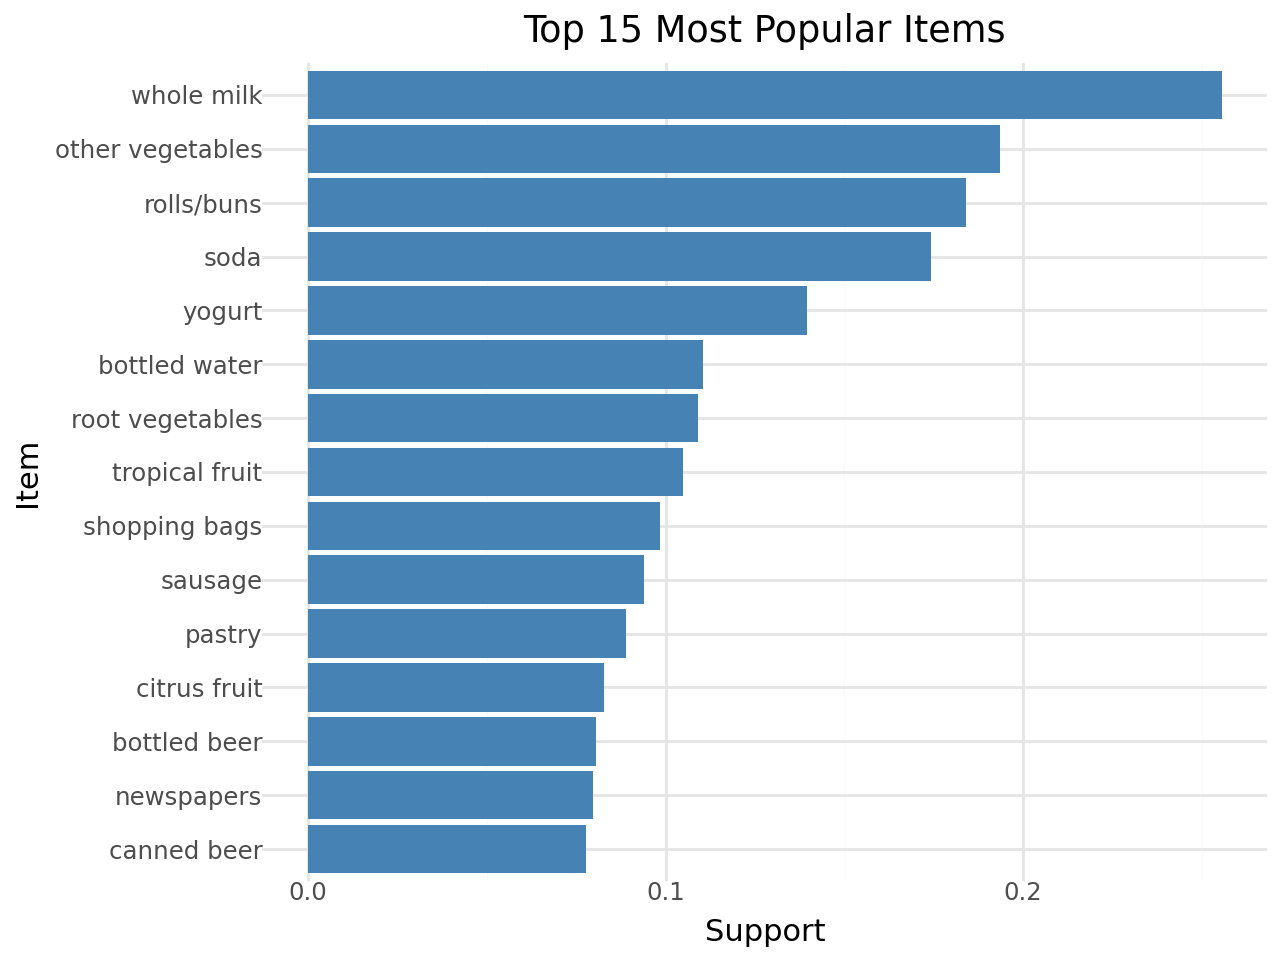

In [32]:
# horizontal bar chart of the 15 most popular items
top_15 = item_support.head(15).reset_index()
top_15.columns = ['item', 'support']

(ggplot(top_15, aes(x='reorder(item, support)', y='support'))
 + geom_col(fill='steelblue')
 + coord_flip()
 + labs(x='Item', y='Support', title='Top 15 Most Popular Items')
 + theme_minimal())

5. Consider the basket sizes and the item supports. Which item is most popular, and in what percentage of baskets does it appear? Which items are most common? What does this suggest about the "popular items co-occur just by chance" problem discussed in the reading?

Whole milk is the most popular item and appears in about 25.55% of baskets. Other common items include other vegetables, rolls/buns, soda, and yogurt. Because these items are individually very common and baskets often contain multiple items, popular items may appear together frequently just by chance. This means that high co-occurrence alone does not necessarily indicate a meaningful association.

6. Consider the rule **{yogurt} → {whole milk}**. Compute and interpret the confidence of this rule.


In [33]:
# {yogurt} → {whole milk}

yogurt = 'yogurt'
whole_milk = 'whole milk'

# Count how many baskets contain yogurt
yogurt_support = basket[yogurt].mean()

# Count how many baskets contain both yogurt and whole milk
both_support = (basket[yogurt] & basket[whole_milk]).mean()

# Confidence = P(whole milk | yogurt)
confidence = both_support / yogurt_support

print(f"Support of {yogurt}: {yogurt_support:.4f} ({yogurt_support * 100:.2f}%)")
print(f"Support of both: {both_support:.4f} ({both_support * 100:.2f}%)")
print(f"Confidence of {yogurt} -> {whole_milk}: {confidence:.4f} ({confidence * 100:.2f}%)")

Support of yogurt: 0.1395 (13.95%)
Support of both: 0.0560 (5.60%)
Confidence of yogurt -> whole milk: 0.4016 (40.16%)


The confidence of {yogurt} → {whole milk} is 40.16%. This means that among baskets containing yogurt, 40.16% also contain whole milk.

7. Compute and interpret the **lift** of {yogurt} → {whole milk}.

In [34]:
# lift of {yogurt} → {whole milk}.

# Support of whole milk
whole_milk_support = basket[whole_milk].mean()

# Lift = support(both) / (support(yogurt) * support(whole milk))
lift = both_support / (yogurt_support * whole_milk_support)

print(f"Support of {whole_milk}: {whole_milk_support:.4f} ({whole_milk_support * 100:.2f}%)")
print(f"Lift of {yogurt} -> {whole_milk}: {lift:.4f}")

Support of whole milk: 0.2555 (25.55%)
Lift of yogurt -> whole milk: 1.5717


The lift of {yogurt} → {whole milk} is 1.5717. This means that baskets containing yogurt are about 1.57 times as likely to contain whole milk compared with baskets overall, indicating a positive association between yogurt and whole milk.

8. Now compute and interpret the confidence and lift for the rule {whole milk} → {yogurt}.

In [35]:
# confidence and lift for the rule {whole milk} → {yogurt}.

# Confidence = P(yogurt | whole milk) = support(both) / support(whole milk)
rev_confidence = both_support / whole_milk_support

# Lift is symmetric, so lift(A -> B) = lift(B -> A)
rev_lift = both_support / (whole_milk_support * yogurt_support)

print(f"Confidence of {whole_milk} -> {yogurt}: {rev_confidence:.4f} ({rev_confidence * 100:.2f}%)")
print(f"Lift of {whole_milk} -> {yogurt}: {rev_lift:.4f}")

Confidence of whole milk -> yogurt: 0.2193 (21.93%)
Lift of whole milk -> yogurt: 1.5717


The confidence of {whole milk} → {yogurt} is 21.93%, meaning that 21.93% of baskets containing whole milk also contain yogurt. The lift is 1.5717, so whole milk and yogurt occur together about 1.57 times as often as would be expected if they were independent. The lift is the same in either direction, while confidence changes depending on which item is the antecedent.

9. Write two functions.

- `support(items, onehot)`: returns the share of baskets that contain **all** of the items in the list `items`.
- `rule_metrics(antecedent, consequent, onehot)`: returns a Pandas Series with the `support`, `confidence`, and `lift` of the rule `antecedent -> consequent`. Both `antecedent` and `consequent` are *lists* of items.

Test the functions on `["yogurt"]` → `["whole milk"]`. The values should match the ones you computed earlier.

In [36]:
def support(items, onehot):
    return onehot[items].all(axis=1).mean()


def rule_metrics(antecedent, consequent, onehot):
    support_a = support(antecedent, onehot)
    support_b = support(consequent, onehot)
    support_both = support(antecedent + consequent, onehot)

    confidence = support_both / support_a
    lift = support_both / (support_a * support_b)

    return pd.Series({"support": support_both, "confidence": confidence, "lift": lift})


rule_metrics(["yogurt"], ["whole milk"], basket)

,0
support,0.056024
confidence,0.401603
lift,1.571735


10. Whole milk is in about a quarter of all baskets. Consider the rules `{X} → {whole milk}` for the five antecedents `X` in the next cell. Before running anything, predict: for which of these will the lift be **above 1**? For which might the confidence look decent but the lift be **close to or below 1**? Just think about this before proceeding.

In [37]:
antecedents = pd.Series(["yogurt", "rolls/buns", "bottled water", "soda", "other vegetables"])

I predict yogurt will have lift above 1 bc we already found a positive association between yogurt and whole milk. I think other vegetables may also have lift above 1.

For common items such as rolls/buns, bottled water, and soda, the confidence may look fairly high because whole milk is already present in about 25% of all baskets, but their lift could be closer to 1 if they don't have a strong association with whole milk.

11. Compute the support, confidence, and lift of `{X} → {whole milk}` for each of the five antecedents above, and display the results sorted by lift (largest first). Compare to your predictions. Hint: Use `apply` with `lambda` on the Series of antecedents.


In [38]:
results = antecedents.apply(lambda x: rule_metrics([x], ["whole milk"], basket))

results.sort_values(by="lift", ascending=False)

,support,confidence,lift
0,0.056024,0.401603,1.571735
4,0.074835,0.386758,1.513634
2,0.034367,0.310948,1.216940
1,0.056634,0.307905,1.205032
3,0.040061,0.229738,0.899112


12. Run `apriori` on `basket` with `min_support=0.01` and store the result in `frequent_itemsets`. Then add a column `n_items` giving the number of items in each itemset.

In [39]:
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)

frequent_itemsets["n_items"] = frequent_itemsets["itemsets"].apply(len)

frequent_itemsets

,support,itemsets,n_items
0,0.033452,(UHT-milk),1
1,0.017692,(baking powder),1
2,0.052466,(beef),1
3,0.033249,(berries),1
4,0.026029,(beverages),1
...,...,...,...
328,0.011998,"(root vegetables, whole milk, tropical fruit)",3
329,0.014540,"(yogurt, root vegetables, whole milk)",3
330,0.010473,"(soda, yogurt, whole milk)",3
331,0.015150,"(yogurt, whole milk, tropical fruit)",3


13. Generate the rules with `make_rules`, keeping rules with confidence of at least 0.20. Store them in `rules` and print how many there are.

In [41]:
rules = association_rules(df=frequent_itemsets, num_itemsets=len(basket), metric="confidence", min_threshold=0.20)

len(rules)

234

14. Make the rules easier to read. Create a copy `rules_display` of `rules` and add three columns:

- `antecedent`: the antecedent items as text, e.g. `"tropical fruit, yogurt"`
- `consequent`: the consequent items as text
- `transactions`: the number of baskets that contain the whole rule (support times the number of baskets, rounded to an integer)

Then display the columns `antecedent`, `consequent`, `support`, `confidence`, `lift`, `transactions` for the first 8 rules.

In [42]:
rules_display = rules.copy()

rules_display["antecedent"] = rules_display["antecedents"].apply(
    lambda x: ", ".join(x))

rules_display["consequent"] = rules_display["consequents"].apply(
    lambda x: ", ".join(x))

rules_display["transactions"] = (
    rules_display["support"] * len(basket)).round().astype(int)

rules_display[
    ["antecedent", "consequent", "support", "confidence", "lift", "transactions"]].head(8)

,antecedent,consequent,support,confidence,lift,transactions
0,beef,other vegetables,0.019725,0.375969,1.943066,194
1,beef,rolls/buns,0.013625,0.259690,1.411858,134
2,beef,root vegetables,0.017387,0.331395,3.040367,171
3,beef,whole milk,0.021251,0.405039,1.585180,209
4,beef,yogurt,0.011693,0.222868,1.597601,115
5,berries,other vegetables,0.010269,0.308869,1.596280,101
6,berries,whole milk,0.011795,0.354740,1.388328,116
7,berries,yogurt,0.010574,0.318043,2.279848,104


15. Show the 10 rules with the highest **confidence**. What do the highest-confidence rules have in common? Why is confidence alone a poor guide here?

In [43]:
rules_display.sort_values(
    by="confidence",
    ascending=False)[
    ["antecedent", "consequent", "support", "confidence", "lift", "transactions"]].head(10)

,antecedent,consequent,support,confidence,lift,transactions
158,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
163,"curd, yogurt",whole milk,0.010066,0.582353,2.279125,99
153,"butter, other vegetables",whole milk,0.011490,0.573604,2.244885,113
222,"root vegetables, tropical fruit",whole milk,0.011998,0.570048,2.230969,118
224,"yogurt, root vegetables",whole milk,0.014540,0.562992,2.203354,143
165,"other vegetables, domestic eggs",whole milk,0.012303,0.552511,2.162336,121
232,"whipped/sour cream, yogurt",whole milk,0.010880,0.524510,2.052747,107
213,"rolls/buns, root vegetables",whole milk,0.012710,0.523013,2.046888,125
171,"pip fruit, other vegetables",whole milk,0.013523,0.517510,2.025351,133


Most of the highest-confidence rules have whole milk as the consequent, with a few having other vegetables. These are already very popular items, so they have a high chance of appearing in a basket regardless of the antecedent.

This is why confidence alone can be misleading. It doesn't account for how common the consequent already is.

16. Show the 10 rules with the highest **lift**. Compare this list with the highest-confidence list. What kinds of products appear now? Look at the `support` and `transactions` columns: how much evidence is each of these rules based on?

In [44]:
rules_display.sort_values(
    by="lift",
    ascending=False)[
    ["antecedent", "consequent", "support", "confidence", "lift", "transactions"]].head(10)

,antecedent,consequent,support,confidence,lift,transactions
157,"other vegetables, citrus fruit",root vegetables,0.010371,0.359155,3.295045,102
209,"yogurt, other vegetables",whipped/sour cream,0.010168,0.234192,3.267062,100
185,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
158,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
188,"other vegetables, whole milk",root vegetables,0.023183,0.309783,2.842082,228
190,root vegetables,"other vegetables, whole milk",0.023183,0.212687,2.842082,228
155,butter,"other vegetables, whole milk",0.011490,0.207339,2.770630,113
164,"curd, whole milk",yogurt,0.010066,0.385214,2.761356,99


The highest-lift rules include more specific combinations of products. Such as root vegetables, citrus fruit, whipped/sour cream, yogurt, and tropical fruit, rather than being dominated by whole milk.

These rules show stronger associations after accounting for how common each product is. However, many have support of only ~1–2% and are based on ~100–228 transactions, so the strongest lift values are based on relatively limited evidence.

17. Create `interesting_rules`: the rules with **confidence of at least 0.30 and lift of at least 1.5**, sorted by lift (largest first).


In [45]:
interesting_rules = rules_display[
    (rules_display["confidence"] >= 0.30) &
    (rules_display["lift"] >= 1.5)].sort_values(
    by="lift",
    ascending=False)

interesting_rules[["antecedent", "consequent", "support", "confidence", "lift", "transactions"]]

,antecedent,consequent,support,confidence,lift,transactions
157,"other vegetables, citrus fruit",root vegetables,0.010371,0.359155,3.295045,102
185,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
158,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
...,...,...,...,...,...,...
89,onions,whole milk,0.012100,0.390164,1.526965,119
72,hygiene articles,whole milk,0.012811,0.388889,1.521975,126
17,brown bread,whole milk,0.025216,0.388715,1.521293,248
105,other vegetables,whole milk,0.074835,0.386758,1.513634,736


18. Choose **one** rule from the table and interpret its **support**, **confidence**, and **lift** with numbers, as you did for {yogurt} → {whole milk}.

The rule {other vegetables, citrus fruit} → {root vegetables} has support of 0.0104, meaning about 1.04% of all baskets, or 102 transactions, contain all three products.

Its confidence is 0.3592, meaning about 35.92% of baskets containing both other vegetables and citrus fruit also contain root vegetables. Its lift is 3.30, meaning baskets containing other vegetables and citrus fruit are about 3.30 times as likely to contain root vegetables as a typical basket.

19. The manager wants to **increase sales of yogurt**. Which products should the store link to yogurt (shelf placement, a joint promotion, a recommendation)?

In [46]:
rules_display[
    rules_display["consequent"] == "yogurt"][
    ["antecedent", "consequent", "support", "confidence", "lift", "transactions"]].sort_values(
    by="lift", ascending=False)

,antecedent,consequent,support,confidence,lift,transactions
164,"curd, whole milk",yogurt,0.010066,0.385214,2.761356,99
231,"whole milk, tropical fruit",yogurt,0.015150,0.358173,2.567516,149
208,"whipped/sour cream, other vegetables",yogurt,0.010168,0.352113,2.524073,100
203,"other vegetables, tropical fruit",yogurt,0.012303,0.342776,2.457146,121
233,"whipped/sour cream, whole milk",yogurt,0.010880,0.337539,2.419607,107
162,"citrus fruit, whole milk",yogurt,0.010269,0.336667,2.413350,101
47,curd,yogurt,0.017285,0.324427,2.325615,170
7,berries,yogurt,0.010574,0.318043,2.279848,104
43,cream cheese,yogurt,0.012405,0.312821,2.242412,122
212,"other vegetables, whole milk",yogurt,0.022267,0.297554,2.132979,219


The store could link yogurt with products like whole milk, tropical fruit, curd, berries, cream cheese, and whipped/sour cream.

These products appear in rules with relatively high lift, meaning customers buying them are more likely than average to also buy yogurt.

For example, baskets containing curd and whole milk are about 2.76x as likely to contain yogurt, while baskets containing whole milk and tropical fruit are about 2.57x as likely. These associations could be used for shelf placement, joint promotions, or recommendations.

---
## References and attribution


- Hahsler, M., Gr&uuml;n, B., and Hornik, K. (2005). arules: A computational environment for mining association rules and frequent item sets. *Journal of Statistical Software*, 14(15). (The R package that distributes the data.)
- Data copy: GitHub repository `stedy/Machine-Learning-with-R-datasets` (`groceries.csv`), the data used in Lantz, B., *Machine Learning with R*.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638. <https://doi.org/10.21105/joss.00638>


**Preparation of this notebook:** drafted with the assistance of generative AI tools (ChatGPT and Claude).